# Task 2.1: How often does the cat qubit bit flip?

**Method.** A bit flip takes seconds, too slow to simulate. Every decay rate is an eigenvalue of the master equation, so we compute the slowest "odd" eigenvalue directly and check it against time-domain fits where those are feasible.

In [1]:
import sys, json, glob
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'research/s2').is_dir())
S2 = ROOT / 'results/s2'
load = lambda pat: [json.loads(Path(f).read_text()) for f in sorted(glob.glob(str(S2 / pat)))]
show = lambda name, w=750: display(Image(filename=str(ROOT / 'figures/s2' / f'{name}.png'), width=w))
sys.path.insert(0, str(ROOT))
from research.s2.common import KAPPA_A
nominal = lambda d: d['eps_z_over_g2'] == 0 and d['n_th'] == 0 and d['kappa_a'] == KAPPA_A and abs(d['kappa_b'] - 16.3363) < 1e-3

def largest(rows):
    best = {}
    for d in rows:
        k = round(d['alpha'], 2)
        if k not in best or d['na'] * d['nb'] > best[k]['na'] * best[k]['nb']:
            best[k] = d
    return best

In [2]:
best = largest(d for d in load('gx_two_*.json') if nominal(d))
pd.DataFrame([{'alpha': a, 'bit flip rate (1/µs)': f"{d['gamma_x']:.2e}", 'time between flips (s)': f"{1e-6 / d['gamma_x']:.2g}", 'size': f"{d['na']}x{d['nb']}"}
              for a, d in sorted(best.items()) if a in (1.0, 1.4, 1.8, 2.1, 2.4)])

,alpha,bit flip rate (1/µs),time between flips (s),size
0,1.0,2.30e-03,0.00043,20x10
1,1.4,1.20e-04,0.0083,22x12
2,1.8,4.07e-06,0.25,26x10
3,2.1,3.85e-07,2.6,28x12
4,2.4,3.12e-08,32,32x10


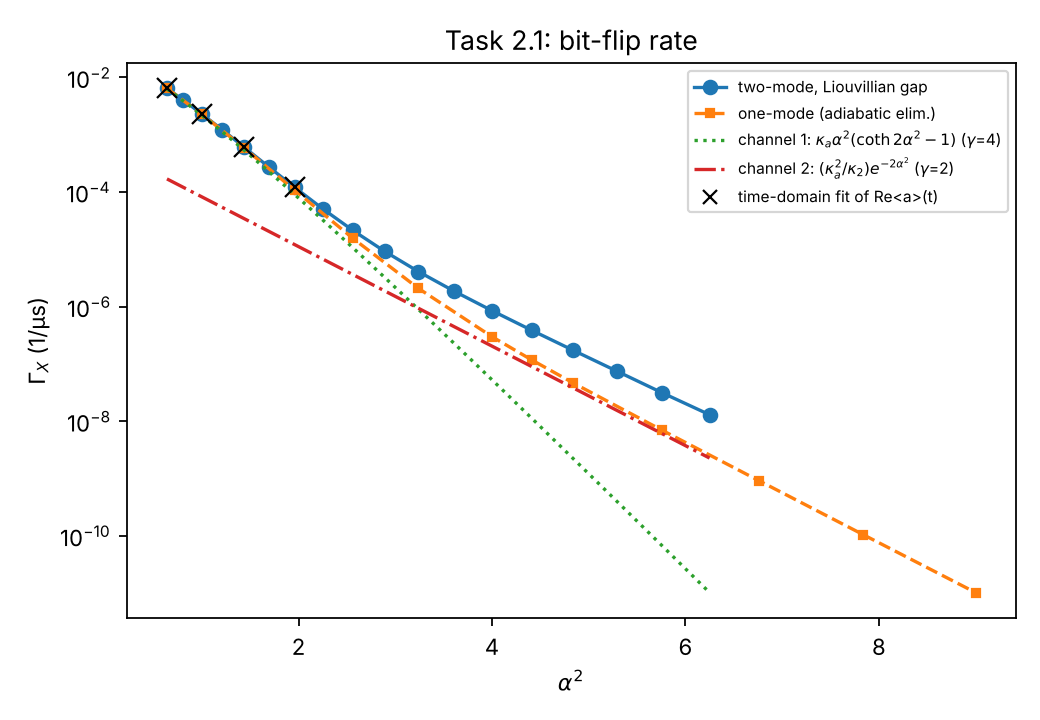

In [3]:
show('gamma_x')

**Result.** About **one flip every 2.6 s** at α = 2.1. The eigenvalue and the brute-force fits (crosses) agree to 2e-8. The curve bends because two escape routes take turns: a direct one (γ = 4) for small cats, an out-and-back one (γ = 2) for large cats. Details: [TECHNICAL.md](../docs/TECHNICAL.md#task-21-γ_x).